# Traffic Volume Prediction

## Modeling 

*Predicting next hour westbound I-94 traffic volume.*

In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv('../data/traffic_clean.csv', parse_dates=['date_time'])
print(data.shape)
print(data['date_time'].diff().value_counts())

(28972, 8)
date_time
0 days 01:00:00    28971
Name: count, dtype: int64


*Load data*

In [2]:
data['hour'] = data['date_time'].dt.hour
data['dayofweek'] = data['date_time'].dt.day_of_week
data['month'] = data['date_time'].dt.month
data['is_weekend'] = (data['dayofweek'] >= 5).astype(int)
data['is_holiday'] = (data['holiday'] != 'No Holiday').astype(int)

print(data[['date_time', 'hour', 'dayofweek', 'month', 'is_weekend', 'is_holiday']].head())
print(data['is_weekend'].mean().round(3), 'share of weekend hours')
print(data['is_holiday'].sum(), 'holiday hours')

            date_time  hour  dayofweek  month  is_weekend  is_holiday
0 2015-06-11 20:00:00    20          3      6           0           0
1 2015-06-11 21:00:00    21          3      6           0           0
2 2015-06-11 22:00:00    22          3      6           0           0
3 2015-06-11 23:00:00    23          3      6           0           0
4 2015-06-12 00:00:00     0          4      6           0           0
0.287 share of weekend hours
840 holiday hours


*Add time features*

In [3]:
def weather_group(desc):
    if pd.isna(desc):
        return np.nan
    if 'thunderstorm' in desc:
        return 'thunderstorm'
    if 'snow' in desc or 'sleet' in desc or 'freezing' in desc:
        return 'snow'
    if 'rain' in desc or 'drizzle' in desc:
        return 'rain'
    if desc in ('mist', 'fog', 'haze', 'smoke'):
        return 'fog'
    if 'clouds' in desc:
        return 'clouds'
    return 'clear'

data['weather_group'] = data['weather_description'].apply(weather_group)
data['weather_group'].value_counts(dropna=False)

weather_group
clear           9636
clouds          8567
rain            3300
fog             2420
NaN             2295
snow            1909
thunderstorm     845
Name: count, dtype: int64

*Group weather descriptions into categories*

In [4]:
for h in [1, 24, 168]:
    data[f'lag_{h}'] = data['traffic_volume'].shift(h)

data['rolling_24'] = data['traffic_volume'].shift(1).rolling(24, min_periods=20).mean()
print(data['rolling_24'].isna().sum())
print(data[['date_time', 'traffic_volume', 'lag_1', 'lag_24', 'rolling_24']].iloc[24:28])
print(data[['lag_1', 'lag_24', 'lag_168', 'rolling_24']].isna().sum())

4801
             date_time  traffic_volume   lag_1  lag_24  rolling_24
24 2015-06-12 20:00:00          3095.0     NaN  2886.0         NaN
25 2015-06-12 21:00:00          3299.0  3095.0     NaN         NaN
26 2015-06-12 22:00:00             NaN  3299.0     NaN         NaN
27 2015-06-12 23:00:00             NaN     NaN     NaN         NaN
lag_1         2339
lag_24        2362
lag_168       2506
rolling_24    4801
dtype: int64


*Add lag features*

In [5]:
features = ['hour', 'dayofweek', 'month', 'is_weekend', 'is_holiday',
            'temp_f', 'rain_1h', 'clouds_all', 'weather_group',
            'lag_1', 'lag_24', 'lag_168', 'rolling_24']
target = 'traffic_volume'

model_data = data.dropna(subset=features + [target]).reset_index(drop=True)
print(len(model_data), 'rows usable for modeling')

train = model_data[model_data['date_time'] < '2018-01-01']
test = model_data[model_data['date_time'] >= '2018-01-01']

print(len(train), 'train rows:', train['date_time'].min(), 'to', train['date_time'].max())
print(len(test), 'test rows:', test['date_time'].min(), 'to', test['date_time'].max())
print(f'test share: {len(test) / len(model_data):.1%}')

22913 rows usable for modeling
16445 train rows: 2015-06-27 18:00:00 to 2017-12-31 23:00:00
6468 test rows: 2018-01-01 00:00:00 to 2018-09-30 23:00:00
test share: 28.2%


*Dropped rows with missing features or targets*

## Models

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{name}: MAE {mae:.0f} | RMSE {rmse:.0f} | R² {r2:.3f}')
    return {'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}
results = []
y_train = train[target]
y_test = test[target]

In [7]:
results.append(evaluate('Naive', y_test, test['lag_168']))

Naive: MAE 339 | RMSE 649 | R² 0.891


In [8]:
predictors = ['hour', 'is_weekend', 'is_holiday', 'temp_f', 'rain_1h',
              'clouds_all', 'lag_1', 'lag_24', 'lag_168', 'rolling_24']
simple_models = {}

for col in predictors:
    model = LinearRegression()
    model.fit(train[[col]], y_train)
    pred = model.predict(test[[col]])

    res = evaluate(f'Simple LR ({col})', y_test, pred)
    res['intercept'] = model.intercept_
    res['slope'] = model.coef_[0]
    results.append(res)
    simple_models[col] = model

Simple LR (hour): MAE 1640 | RMSE 1843 | R² 0.124
Simple LR (is_weekend): MAE 1695 | RMSE 1925 | R² 0.044
Simple LR (is_holiday): MAE 1717 | RMSE 1964 | R² 0.004
Simple LR (temp_f): MAE 1705 | RMSE 1959 | R² 0.010
Simple LR (rain_1h): MAE 1722 | RMSE 1969 | R² -0.001
Simple LR (clouds_all): MAE 1698 | RMSE 1950 | R² 0.019
Simple LR (lag_1): MAE 599 | RMSE 798 | R² 0.836
Simple LR (lag_24): MAE 626 | RMSE 996 | R² 0.744
Simple LR (lag_168): MAE 355 | RMSE 641 | R² 0.894
Simple LR (rolling_24): MAE 1700 | RMSE 1935 | R² 0.034


*Simple LR*

In [9]:
results_table = pd.DataFrame(results).set_index('model').round(3)
results_table.sort_values('RMSE')

,MAE,RMSE,R2,intercept,slope
model,,,,,
Simple LR (lag_168),354.526,641.154,0.894,144.578,0.955
Naive,339.167,648.653,0.891,NaN,NaN
Simple LR (lag_1),598.510,797.876,0.836,283.908,0.914
Simple LR (lag_24),626.332,995.946,0.744,432.435,0.869
Simple LR (hour),1639.840,1842.684,0.124,2124.536,101.237
Simple LR (is_weekend),1695.045,1925.078,0.044,3542.500,-877.159
Simple LR (rolling_24),1699.664,1934.919,0.034,1048.101,0.678
Simple LR (clouds_all),1697.997,1949.748,0.019,3064.120,5.532
Simple LR (temp_f),1704.506,1958.979,0.010,2607.663,12.984


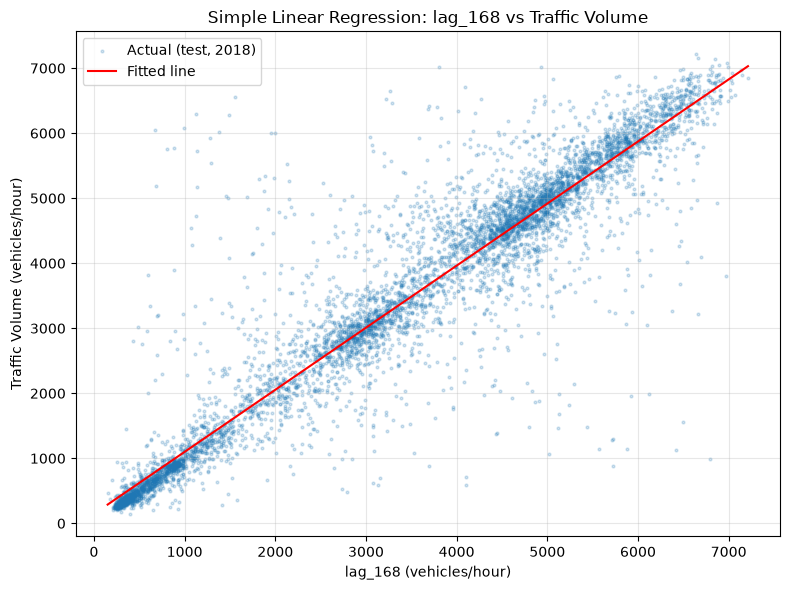

In [10]:
import matplotlib.pyplot as plt

best = 'lag_168'
line_x = pd.DataFrame({best: [test[best].min(), test[best].max()]})
plt.figure(figsize=(8, 6))
plt.scatter(test[best], y_test, s=4, alpha=0.2, label='Actual (test, 2018)')
plt.plot(line_x[best], simple_models[best].predict(line_x), color='red', label='Fitted line')
plt.title(f'Simple Linear Regression: {best} vs Traffic Volume')
plt.xlabel(f'{best} (vehicles/hour)')
plt.ylabel('Traffic Volume (vehicles/hour)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/simple_lr_best.png', dpi=150)
plt.show()